# Volve → OSDU: evaluation report

An agent converts Equinor's open **Volve** well data (LAS logs, well paths, petrophysical report
PDFs) into validated **OSDU** records. This notebook evaluates it on 13 wellbores against
independent ground truth (Norwegian Offshore Directorate headers, Equinor's well picks), next to a
rules-only baseline and a single-prompt LLM baseline.

Every number below is computed from `docs/results.json`, which `uv run volve-osdu eval` writes;
nothing is typed by hand. Regenerate with `uv run --group notebook python scripts/make_notebook.py`.
The same content as an interactive page: `docs/report.html`.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from volve_osdu.eval.conflicts import load_conflicts
from volve_osdu.eval.metrics import load_curve_labels
from volve_osdu.eval.reportdata import (RUN1_ROWS, SYSTEMS, datum_checks, f12_curve_ranges,
                                        load_results, run1_values)

for name in ("lasio", "lasio.las", "lasio.reader"):  # silence notes about wrapped LAS files
    logging.getLogger(name).setLevel(logging.ERROR)
pd.set_option("display.colheader_justify", "left")

doc = load_results()
res, meta = doc["systems"], doc["meta"]
S = {s: res[s]["summary"] for s in SYSTEMS}

# Colour-blind-safe categorical slots (validated set), one fixed colour per system.
COLOR = {"rules": "#2a78d6", "llm_only": "#eb6834", "agent": "#1baf7a"}
INK, INK2, MUTED, GRID, ALERT = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#d03b3b"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": INK2,
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})

def pct(x):
    return "n/a" if x is None else f"{100 * x:.0f}%"

def ci(e):
    return f"{pct(e['value'])} (95% CI {pct(e['low'])}–{pct(e['high'])}; {e['numerator']}/{e['denominator']})"

print(f"Results generated {meta['date']} at commit {meta['commit']}; model: {res['agent']['model']}")

Results generated 2026-11-08 16:14 UTC at commit 49fc55a; model: qwen3-4b-8k


## Summary

In [2]:
a, lo = S["agent"], S["llm_only"]
display(Markdown(f"""
| | |
|---|---|
| **Header values correct (agent)** | {ci(a['field_accuracy'])} |
| **Facts read from report prose** | agent {ci(a['report_fact_accuracy'])} · single-prompt LLM {ci(lo['report_fact_accuracy'])} |
| **Emitted values found in no input** | {a['hallucination_rate']['numerator']} of {a['hallucination_rate']['denominator']} (agent) |
| **Conflicts routed to review** | {a['flag_recall']['numerator']}/{a['flag_recall']['denominator']} known + injected, {len(a['false_flags'])} false flags |
| **Valid OSDU manifests** | {a['validation_pass_rate']['numerator']}/{a['validation_pass_rate']['denominator']} wellbores |
"""))


| | |
|---|---|
| **Header values correct (agent)** | 91% (95% CI 78%–100%; 48/53) |
| **Facts read from report prose** | agent 88% (95% CI 57%–100%; 14/16) · single-prompt LLM 25% (95% CI 6%–50%; 4/16) |
| **Emitted values found in no input** | 0 of 69 (agent) |
| **Conflicts routed to review** | 19/19 known + injected, 0 false flags |
| **Valid OSDU manifests** | 13/13 wellbores |


## 1. What is compared

All three systems share parsing, record building (Equinor's `osdu-python-models`) and
validation; they differ only in the judgement steps: which wellbore the files describe, facts from
report prose, and curve mapping.

- **rules**: regex on report text and a static curve dictionary, no LLM
- **llm_only**: one prompt per wellbore, no retrieval, lookup or retries
- **agent**: LangGraph graph with focused prompts, page retrieval, reference-list lookup and up to
  two retries carrying the validator's error message

Gold values that some input states are scored for **accuracy**; values no input states must be
left empty (**abstention**); values where the inputs disagree with NPD are **disputed** and
reported, never scored. 95% confidence intervals: bootstrap over wellbores, 2,000 resamples.

## 2. Headline metrics

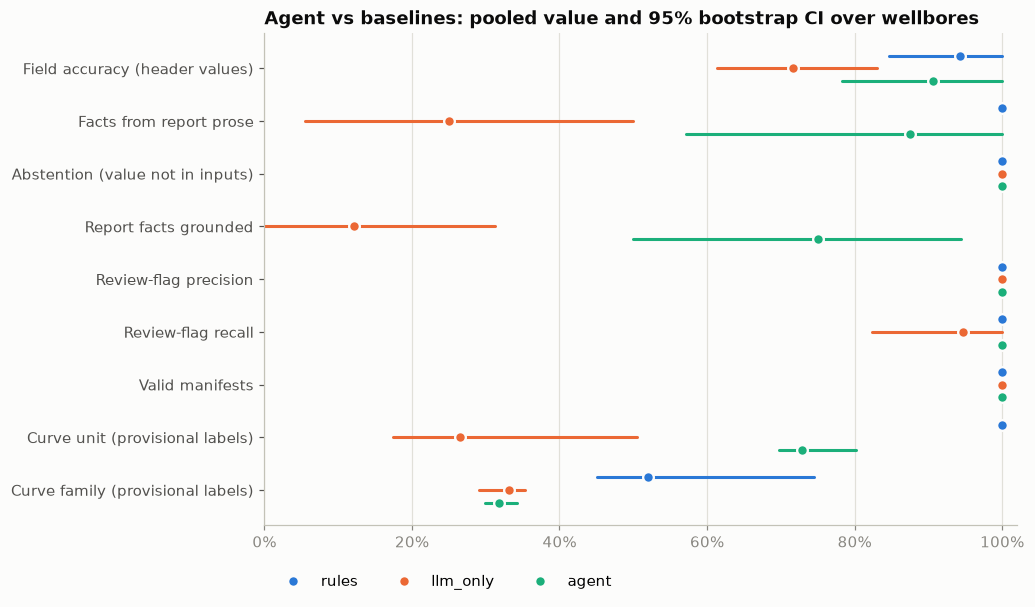

,rules,llm_only,agent
Field accuracy (header values),94% (95% CI 85%–100%; 50/53),72% (95% CI 61%–83%; 38/53),91% (95% CI 78%–100%; 48/53)
Facts from report prose,100% (95% CI 100%–100%; 16/16),25% (95% CI 6%–50%; 4/16),88% (95% CI 57%–100%; 14/16)
Abstention (value not in inputs),100% (95% CI 100%–100%; 27/27),100% (95% CI 100%–100%; 27/27),100% (95% CI 100%–100%; 27/27)
Report facts grounded,n/a (95% CI n/a–n/a; 0/0),12% (95% CI 0%–31%; 4/33),75% (95% CI 50%–94%; 27/36)
Review-flag precision,100% (95% CI 100%–100%; 19/19),100% (95% CI 100%–100%; 18/18),100% (95% CI 100%–100%; 19/19)
Review-flag recall,100% (95% CI 100%–100%; 19/19),95% (95% CI 82%–100%; 18/19),100% (95% CI 100%–100%; 19/19)
Valid manifests,100% (95% CI 100%–100%; 13/13),100% (95% CI 100%–100%; 13/13),100% (95% CI 100%–100%; 13/13)
Curve unit (provisional labels),100% (95% CI 100%–100%; 816/816),26% (95% CI 17%–51%; 216/816),73% (95% CI 70%–80%; 595/816)
Curve family (provisional labels),52% (95% CI 45%–74%; 424/816),33% (95% CI 29%–35%; 271/816),32% (95% CI 30%–34%; 260/816)


In [3]:
rows = [("field_accuracy", "Field accuracy (header values)"),
        ("report_fact_accuracy", "Facts from report prose"),
        ("abstention_accuracy", "Abstention (value not in inputs)"),
        ("grounding_final", "Report facts grounded"),
        ("flag_precision", "Review-flag precision"),
        ("flag_recall", "Review-flag recall"),
        ("validation_pass_rate", "Valid manifests"),
        ("curve_unit_accuracy", "Curve unit (provisional labels)"),
        ("curve_family_accuracy", "Curve family (provisional labels)")]

fig, ax = plt.subplots(figsize=(9.5, 5.6))
for i, (key, label) in enumerate(rows):
    for j, s in enumerate(SYSTEMS):
        e = S[s][key]
        if e["value"] is None:
            continue
        y = i + (j - 1) * 0.24
        ax.plot([e["low"], e["high"]], [y, y], color=COLOR[s], lw=2, solid_capstyle="round")
        ax.plot(e["value"], y, "o", ms=7, color=COLOR[s], mec="#fcfcfb", mew=1.5,
                label=s if i == 0 else None)
ax.set_yticks(range(len(rows)), [r[1] for r in rows])
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
ax.grid(axis="y", visible=False)
ax.set_title("Agent vs baselines: pooled value and 95% bootstrap CI over wellbores")
ax.legend(loc="lower left", ncols=3, bbox_to_anchor=(0, -0.16))
plt.tight_layout()
plt.show()

pd.DataFrame({s: [ci(S[s][k]) for k, _ in rows] for s in SYSTEMS},
             index=[label for _, label in rows])

**Caveats.** The rules baseline's regexes were written after reading these same reports (there
is no held-out set), so its scores are an optimistic upper bound for hand-written rules on this
data. Curve labels are AI-drafted and await owner review; they share conventions with the rules
dictionary, so curve numbers are provisional.

## 3. Accuracy per field

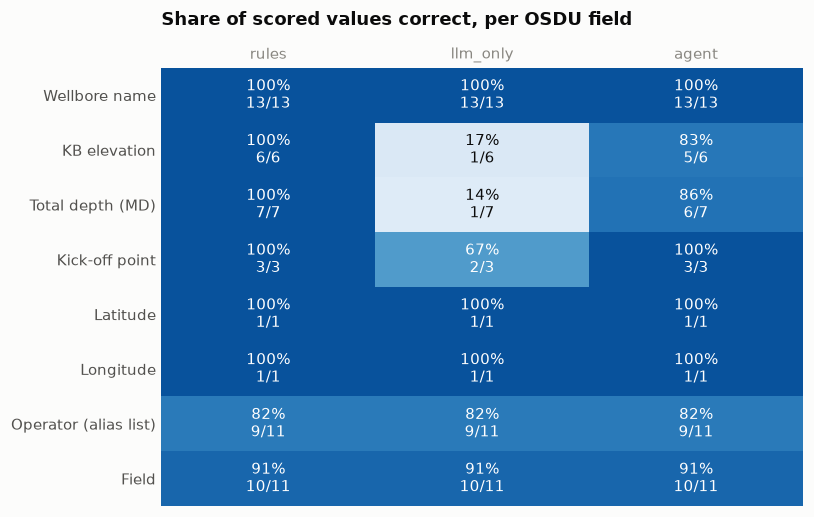

In [4]:
facts = {"wellbore_name": "Wellbore name", "kb_elevation_m": "KB elevation",
         "td_md_m": "Total depth (MD)", "kop_md_m": "Kick-off point", "latitude": "Latitude",
         "longitude": "Longitude", "operator": "Operator (alias list)", "field": "Field"}
vals = np.array([[S[s]["per_fact"][f]["value"] for s in SYSTEMS] for f in facts], dtype=float)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.imshow(vals, cmap="Blues", vmin=0, vmax=1.15, aspect="auto")
for r, f in enumerate(facts):
    for c, s in enumerate(SYSTEMS):
        e = S[s]["per_fact"][f]
        ax.text(c, r, f"{pct(e['value'])}\n{e['numerator']}/{e['denominator']}", ha="center",
                va="center", fontsize=9.5, color="white" if e["value"] >= 0.6 else INK)
ax.set_xticks(range(3), SYSTEMS)
ax.set_yticks(range(len(facts)), facts.values())
ax.tick_params(length=0)
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.xaxis.tick_top()
ax.set_title("Share of scored values correct, per OSDU field", pad=28)
plt.tight_layout()
plt.show()

The gap is in the fields that live in report prose (KB elevation, total depth, kick-off point):
one report often covers three sibling wellbores, and each fact must be attributed to the right one.
Header fields are parsed by code for every system and score alike.

## 4. Grounding: proposed vs kept

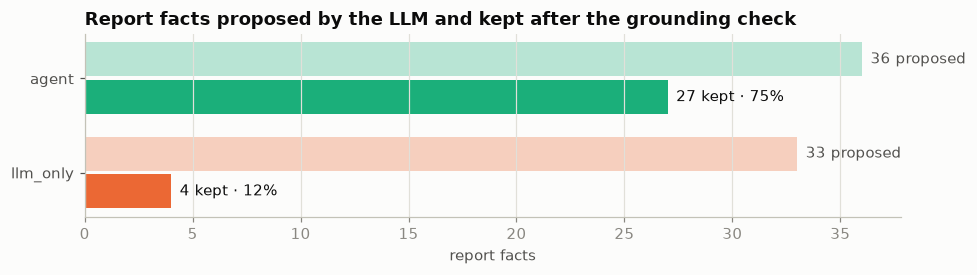

In [5]:
fig, ax = plt.subplots(figsize=(9, 2.6))
for i, s in enumerate(["llm_only", "agent"]):
    e = S[s]["grounding_final"]
    ax.barh(i + 0.2, e["denominator"], height=0.36, color=COLOR[s], alpha=0.3)
    ax.barh(i - 0.2, e["numerator"], height=0.36, color=COLOR[s])
    ax.text(e["denominator"] + 0.4, i + 0.2, f"{e['denominator']} proposed", va="center", color=INK2)
    ax.text(e["numerator"] + 0.4, i - 0.2, f"{e['numerator']} kept · {pct(e['value'])}", va="center", color=INK)
ax.set_yticks([0, 1], ["llm_only", "agent"])
ax.set_xlabel("report facts")
ax.grid(axis="y", visible=False)
ax.set_title("Report facts proposed by the LLM and kept after the grounding check")
plt.tight_layout()
plt.show()

A report fact is kept only if its quote is verbatim on the page, contains the value, states the
right kind of fact and names the right wellbore. Rejected values never reach a record; they are
dropped and listed for human review.

## 5. Human review: are conflicts caught?

In [6]:
found = {s: {tuple(d) for d in S[s]["detected"]} for s in SYSTEMS}
table = pd.DataFrame([
    {"bundle": c.bundle, "type": "real" if c.kind == "known" else "injected",
     "expected flag": c.reason, "what it is": c.description[:70],
     **{s: "✓ flagged" if (c.bundle, c.fact, c.reason) in found[s] else "✗ missed" for s in SYSTEMS}}
    for c in load_conflicts()])
print("False flags:", {s: S[s]["false_flags"] for s in SYSTEMS})
table

False flags: {'rules': [], 'llm_only': [], 'agent': []}


,bundle,type,expected flag,what it is,rules,llm_only,agent
0,15_9-F12,real,log_below_survey,WLC_PETRO_COMPUTED_INPUT_1.LAS GR reaches 4186...,✓ flagged,✓ flagged,✓ flagged
1,15_9-19SR,real,conflict,159-19SR_LFP.las FLD=VOLVE vs STAT1990 composi...,✓ flagged,✓ flagged,✓ flagged
2,15_9-19SR,real,conflict,159-19SR_LFP.las COMP=STATOIL PETROLEUM AS vs ...,✓ flagged,✓ flagged,✓ flagged
3,P01,injected,unit_converted,INPUT LAS depths converted to feet,✓ flagged,✓ flagged,✓ flagged
4,P01,real,log_below_survey,inherited from 15_9-F12: WLC_PETRO_COMPUTED_IN...,✓ flagged,✓ flagged,✓ flagged
5,P02,injected,outside_volve,LAT and LON swapped in both LAS files,✓ flagged,✓ flagged,✓ flagged
6,P02,real,log_below_survey,inherited from 15_9-F12: WLC_PETRO_COMPUTED_IN...,✓ flagged,✓ flagged,✓ flagged
7,P03,injected,conflict,KB elevation 54.9 -> 59.9 m in the OUTPUT LAS ...,✓ flagged,✓ flagged,✓ flagged
8,P03,real,log_below_survey,inherited from 15_9-F12: WLC_PETRO_COMPUTED_IN...,✓ flagged,✓ flagged,✓ flagged
9,P04,injected,plan_not_actual,actual well path renamed to a PLAN,✓ flagged,✓ flagged,✓ flagged


## 6. What the evaluation found in Equinor's data

### A log deeper than the well

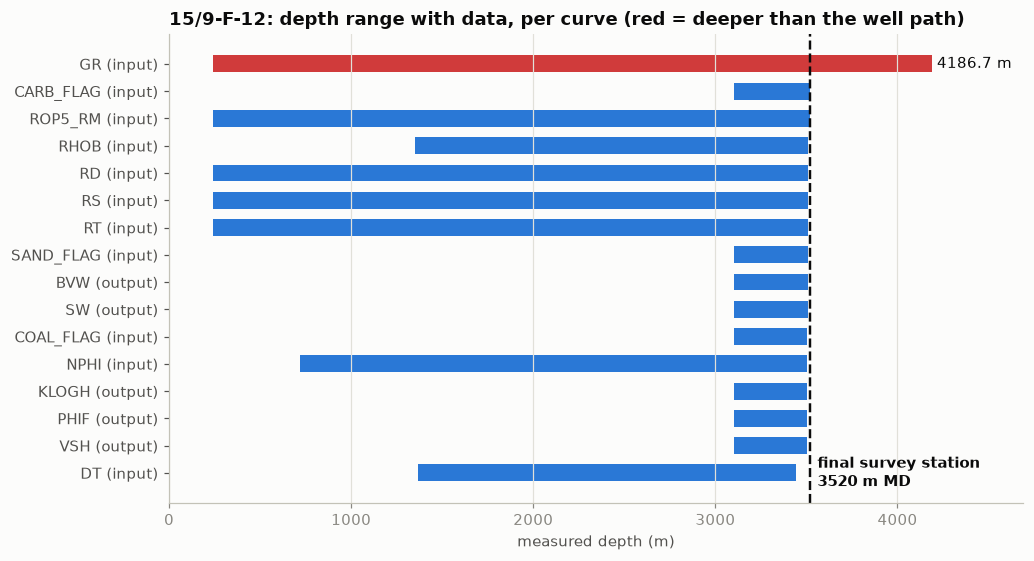

**GR** has data to **4186.7 m** MD, 666.7 m below the final survey station at 3520 m.

In [7]:
curves, survey = f12_curve_ranges()
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for i, c in enumerate(curves):
    deep = c.base_md > survey + 5
    ax.barh(i, c.base_md - c.top_md, left=c.top_md, height=0.62,
            color=ALERT if deep else COLOR["rules"])
    if deep:
        ax.text(c.base_md + 30, i, f"{c.base_md:.1f} m", va="center", color=INK)
ax.axvline(survey, color=INK, lw=1.6, ls="--")
ax.text(survey + 40, len(curves) - 1, f"final survey station\n{survey:.0f} m MD", va="center", color=INK, fontweight="bold")
ax.set_xlim(0, max(c.base_md for c in curves) * 1.12)
ax.set_yticks(range(len(curves)), [f"{c.mnemonic} ({c.file})" for c in curves])
ax.invert_yaxis()
ax.set_xlabel("measured depth (m)")
ax.grid(axis="y", visible=False)
ax.set_title("15/9-F-12: depth range with data, per curve (red = deeper than the well path)")
plt.tight_layout()
plt.show()
gr = curves[0]
display(Markdown(f"**{gr.mnemonic}** has data to **{gr.base_md:.1f} m** MD, "
                 f"{gr.base_md - survey:.1f} m below the final survey station at {survey:.0f} m."))

### Mixed coordinate datums

No LAS header states a datum. The comparison with NPD shows which one each file uses:

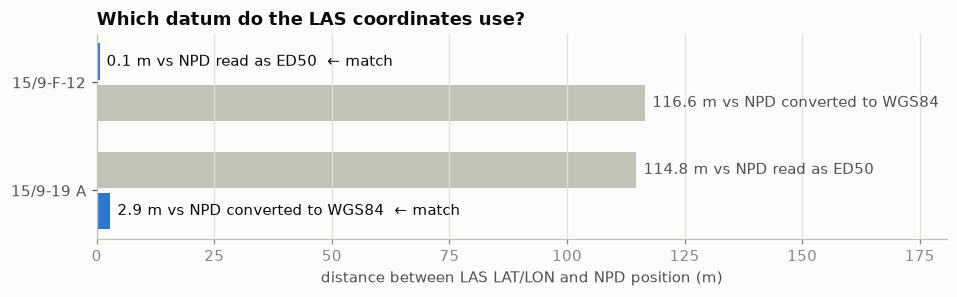

In [8]:
checks = datum_checks()
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, d in enumerate(checks):
    for k, (label, value) in enumerate((("vs NPD read as ED50", d.vs_ed50_m),
                                        ("vs NPD converted to WGS84", d.vs_wgs84_m))):
        y = i + (k - 0.5) * 0.38
        match = value < 10
        ax.barh(y, max(value, 0.6), height=0.34, color=COLOR["rules"] if match else "#c3c2b7")
        ax.text(max(value, 0.6) + 1.5, y, f"{value:.1f} m {label}" + ("  ← match" if match else ""),
                va="center", color=INK if match else INK2)
ax.set_yticks(range(len(checks)), [d.wellbore for d in checks])
ax.invert_yaxis()
ax.set_xlim(0, max(max(d.vs_ed50_m, d.vs_wgs84_m) for d in checks) * 1.55)
ax.set_xlabel("distance between LAS LAT/LON and NPD position (m)")
ax.grid(axis="y", visible=False)
ax.set_title("Which datum do the LAS coordinates use?")
plt.tight_layout()
plt.show()

### Where inputs and the registry disagree (disputed gold, not scored)

In [9]:
lookup = {s: {(o["wellbore"], o["fact"]): o["predicted"] for o in res[s]["outcomes"] if o["kind"] == "disputed"}
          for s in SYSTEMS}
pd.DataFrame([
    {"wellbore": o["wellbore"], "fact": o["fact"], "NPD": o["gold"],
     **{s: "(left empty)" if lookup[s][(o["wellbore"], o["fact"])] is None
        else f'{lookup[s][(o["wellbore"], o["fact"])]:g}' for s in SYSTEMS},
     "why they differ": o["note"]}
    for o in res["rules"]["outcomes"] if o["kind"] == "disputed"])

,wellbore,fact,NPD,rules,llm_only,agent,why they differ
0,15/9-19 A,latitude,58.435903,58.4353,58.4353,58.4353,LAS LAT/LON are WGS84 (NPD's ED50 position shi...
1,15/9-19 A,longitude,1.929736,1.92816,1.92816,1.92816,LAS LAT/LON are WGS84; NPD gives ED50
2,15/9-19 SR,kb_elevation_m,22.0,25,25,25,the 15/9-19 SR LAS (LFP) says KB 25.0 m; NPD s...
3,15/9-19 SR,latitude,58.435903,58.4353,58.4353,58.4353,LAS LAT/LON are WGS84; NPD gives ED50
4,15/9-19 SR,longitude,1.929736,1.92816,1.92816,1.92816,LAS LAT/LON are WGS84; NPD gives ED50
5,15/9-F-1 B,kop_md_m,2604.0,2617,(left empty),2617,F-1 petrophysical report says KOP 2617 m MD RK...
6,15/9-F-11,td_md_m,4562.0,347,(left empty),347,NPD's 4562 m is the TD of technical sidetrack ...
7,15/9-F-11 A,kop_md_m,2578.0,2586,(left empty),2586,F-11 report says KOP 2586 m MD RKB; NPD says 2578
8,15/9-F-11 B,kop_md_m,2586.0,2585,(left empty),2585,F-11 report says KOP 2585 m MD RKB; NPD says 2586
9,15/9-F-12,kb_elevation_m,54.0,54.9,54.9,54.9,Both F-12 LAS files say 54.9 m KB; NPD says 54.0


## 7. Iterations, reported openly

Agent run 1 exposed facts that were quoted verbatim but were the wrong kind of fact or the wrong
wellbore (total depth taken as KB elevation; a sidetrack's kick-off point given to its parent). The
grounding rule gained generic checks (fact keyword, plausible range, wellbore attribution); prompts
were not changed. Run 1's full report: `docs/results_agent_run1.md`.

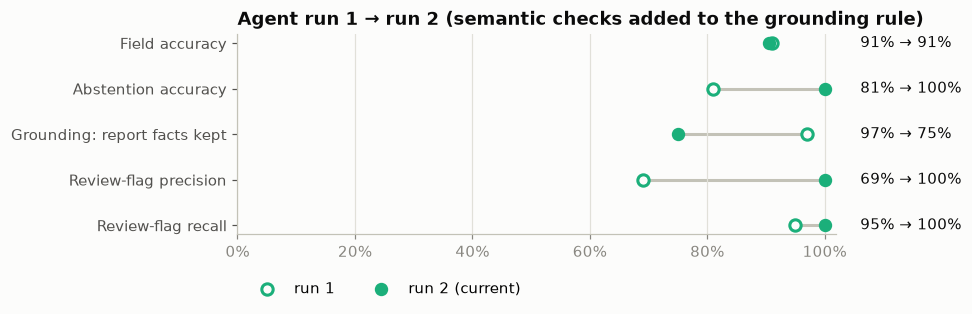

In [10]:
before = run1_values()
labels = {v: k for k, v in RUN1_ROWS.items()}
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (key, b) in enumerate(before.items()):
    a_ = S["agent"][key]["value"]
    ax.plot([b, a_], [i, i], color="#c3c2b7", lw=2, zorder=1)
    ax.scatter([b], [i], s=55, facecolor="#fcfcfb", edgecolor=COLOR["agent"], lw=2, zorder=2,
               label="run 1" if i == 0 else None)
    ax.scatter([a_], [i], s=60, color=COLOR["agent"], zorder=3, label="run 2 (current)" if i == 0 else None)
    ax.text(1.04, i, f"{pct(b)} → {pct(a_)}", va="center", color=INK, transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(before)), [labels[k] for k in before])
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
ax.grid(axis="y", visible=False)
ax.set_title("Agent run 1 → run 2 (semantic checks added to the grounding rule)")
ax.legend(loc="lower left", ncols=2, bbox_to_anchor=(0, -0.38))
plt.tight_layout()
plt.show()

Stricter checks lowered the grounding rate: run 1 counted those wrong-but-quoted facts as
grounded. Other changes made after looking at results: an identity fallback (most specific header
name, flagged) and a lenient parser for the llm_only baseline, so it is judged on its answers.

## 8. Cost and reproducibility

In [11]:
labels_reviewed = sum(r["reviewed"] == "true" for r in load_curve_labels().values())
print(f"Curve labels reviewed by the owner: {labels_reviewed}/{len(load_curve_labels())}")
pd.DataFrame([{"system": s, "model": res[s]["model"] or "-",
               "LLM calls / wellbore": round(S[s]["llm"]["calls_per_wellbore"], 1),
               "tokens / wellbore": round(S[s]["llm"]["tokens_per_wellbore"]),
               "model seconds / wellbore": round(S[s]["llm"]["seconds_per_wellbore"]),
               "wellbores with retries": S[s]["llm"]["retries"]} for s in SYSTEMS]).set_index("system")

Curve labels reviewed by the owner: 0/269


,model,LLM calls / wellbore,tokens / wellbore,model seconds / wellbore,wellbores with retries
system,,,,,
rules,-,0.0,0,0,0
llm_only,qwen3-4b-8k,1.0,3678,69,0
agent,qwen3-4b-8k,7.8,11811,194,12


Model time is measured on a laptop GPU (RTX 3050 Ti, 4 GB) running a 4B model through Ollama,
temperature 0. Every LLM call is cached on disk (key = model + messages + parameters); re-running
the evaluation makes no LLM calls and reproduces every number.

## 9. Limitations

- **Small n**: 13 wellbores, header gold for 11; some fields have only a handful of values.
- **No held-out development set**: the rules baseline and the semantic grounding checks were shaped
  after seeing these bundles; both agent runs are reported.
- **Provisional curve labels** until the owner reviews them; curve mapping is the weakest area for a
  4B model (many rock-physics curves are left unmapped rather than guessed).
- **Assumptions**: the coordinate datum is assumed and flagged; ACL and legal tags are placeholders;
  no real OSDU instance is called.
- **Scope**: LAS, PDF text and well paths; DLIS files, Word reports, formation tops and image-only
  report pages are not read.

*Data: Equinor Volve open dataset, credit "Equinor and the Volve licence partners" (Equinor Open
Data Licence); ground truth: Norwegian Offshore Directorate (NLOD).*